In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import ICIW_Plots
from scipy.integrate import odeint
from HSA_Cam_A_005 import (
    Chem,
    bmodel,
    plot_true_data,
    plot_observed_data,
    plot_inference,
    plot_model_trace,
    theta_true,
    y0_true,
    sigma,
)
import xarray

In [2]:
plt.style.use("ICIWstyle")

<xarray.DataArray 'temperature' (temperature: 6)> Size: 48B
array([250, 280, 300, 320, 350, 400])
Coordinates:
  * temperature  (temperature) int64 48B 250 280 300 320 350 400

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


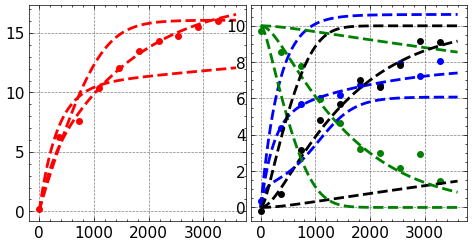

In [3]:
times = np.linspace(0, 1 * 60 * 60, 100)

y_true = xarray.DataArray(
    np.zeros((6, len(times), 4)),
    dims=["temperature", "time", "state"],
    coords={
        "temperature": [250, 280, 300, 320, 350, 400],
        "time": times,
        "state": ["n_g_con", "c_Al", "c_Bl", "c_Cl"],
    },
)
display(y_true.coords["temperature"])

for i, T in enumerate(y_true.coords["temperature"]):
    theta = (
        theta_true[0],
        T,
        theta_true[2],
        theta_true[3],
        theta_true[4],
    )
    y_true[i, :, :] = odeint(
        Chem.reaction, t=times, y0=y0_true, args=(np.array(theta),)
    )
y_true[:, :, 0] *= 1000  # convert m3 to L H2 used (up to a constant atleast)

# Add noise
t_obs = times[::10]
y_obs = np.random.normal(y_true[2, :, :], sigma)[::10, :]  # downsample and add noise

## Plotting the base model
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)
plot_true_data(axs, times, y_true[0, :, :])
plot_true_data(axs, times, y_true[2, :, :])
plot_true_data(axs, times, y_true[4, :, :])
plot_observed_data(axs, t_obs, y_obs)
plt.show()

In [4]:
model = bmodel(t_obs, y_obs)
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000, random_seed=23489)

Sampling: [A0, EA, LH2, kla, sigma]


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")


Plotting sample 1/25
theta: (1000000.0, 300, np.float64(0.007336981092320299), np.float64(3.002252504567321e-05), np.float64(61328.40160521453))
Plotting sample 2/25
theta: (1000000.0, 300, np.float64(0.004720894704780657), np.float64(0.0006060144305668028), np.float64(54430.586977310064))
Plotting sample 3/25
theta: (1000000.0, 300, np.float64(0.0030939173249323326), np.float64(7.794221163380128e-05), np.float64(57441.378407136))
Plotting sample 4/25
theta: (1000000.0, 300, np.float64(0.000464846594793395), np.float64(0.00016115651442061705), np.float64(60591.60202452755))
Plotting sample 5/25
theta: (1000000.0, 300, np.float64(0.010688068573718337), np.float64(0.0010304801110467396), np.float64(56709.15402144102))
Plotting sample 6/25
theta: (1000000.0, 300, np.float64(0.00690779409756036), np.float64(0.00018615832267665112), np.float64(61635.645847296575))
Plotting sample 7/25
theta: (1000000.0, 300, np.float64(0.009321087694877042), np.float64(0.00014359095658113982), np.float64(60

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


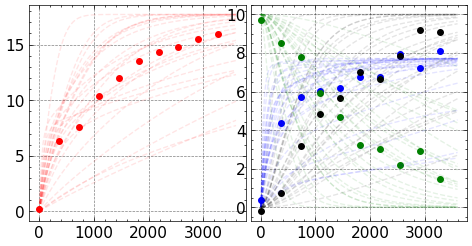

In [5]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)
plot_observed_data(axs, t_obs, y_obs)
plot_inference(
    axs,
    prior_idata,
    times=times,
    num_samples=25,
    lw=1,
    alpha=0.1,
)

In [11]:
try:
    posterior_idata = az.from_netcdf("HSA_Cam_A_004_posterior.nc")
    print("Loaded posterior from file.")
except FileNotFoundError:
    vars_list = list(model.values_to_rvs.keys())[:-1]
    with model:
        posterior_idata = pm.sample(
            step=[pm.DEMetropolisZ(vars_list)],
            draws=10000,
            tune=2000,
            # target_accept=0.9,
            random_seed=23489,
            return_inferencedata=True,
            # nuts_sampler="numpyro",
        )
    posterior_idata.to_netcdf("HSA_Cam_A_004_posterior.nc")

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
DEMetropolisZ: [kla, A0, EA, sigma]
Could not pickle model, sampling singlethreaded.
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [kla, A0, EA, sigma]


Output()

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Sampling 4 chains for 2_000 tune and 10_000 draw iterations (8_000 + 40_000 draws total) took 64 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


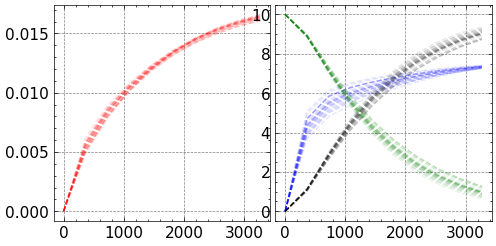

In [7]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    num_samples=25,
    var_names=["y_hat"],
)
# display(post_data)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)

for i in range(25):
    # print(f"Plotting sample {i+1}/25")
    plot_true_data(
        axs,
        t_obs,
        post_data.values[:, :, i],
        lw=1,
        alpha=0.1,
    )
plt.show()

<xarray.DataArray 'y_hat' (y_hat_dim_0: 10, y_hat_dim_1: 4, sample: 40000)> Size: 13MB
array([[[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [1.00000000e+01, 1.00000000e+01, 1.00000000e+01, ...,
         1.00000000e+01, 1.00000000e+01, 1.00000000e+01],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00]],

       [[4.63724036e-03, 5.69253166e-03, 5.24825102e-03, ...,
         5.96045529e-03, 5.96045529e-03, 5.96045529e-03],
        [3.45184258e+00, 4.58576422e+00, 4.16070677e+00, ...,
         5.01214012e+00, 5.01214012e+00, 5.01214012e+00],
        [8.81460222e+00, 8.89323256e+00, 8.91245575e+00, ...,
         9.05168483e+00, 9.05168483e+00, 9.05168483e+00],
        [1.18539778e+00, 1.10676744e+00, 1.08754425e+00, ...,
         9.48315167e-01, 9.48315167e-01, 9.48315167e-01]],

       [[7.64362362e-03, 8.56298045e-03, 8.16637212e-03, ...,
         8.58811411e-03, 8.58811411e-03, 8.58811411e-03],
...
         7.42530130e+00, 7.42530130e+00, 7.42530130e+00]],

       [[1.62262590e-02, 1.58731941e-02, 1.59093823e-02, ...,
         1.52331008e-02, 1.52331008e-02, 1.52331008e-02],
        [7.02654602e+00, 7.25662774e+00, 7.16325509e+00, ...,
         7.28024345e+00, 7.28024345e+00, 7.28024345e+00],
        [8.00287065e-01, 1.38343361e+00, 1.25387282e+00, ...,
         2.04714265e+00, 2.04714265e+00, 2.04714265e+00],
        [9.19971294e+00, 8.61656639e+00, 8.74612718e+00, ...,
         7.95285735e+00, 7.95285735e+00, 7.95285735e+00]],

       [[1.67066133e-02, 1.63416257e-02, 1.63960308e-02, ...,
         1.57412615e-02, 1.57412615e-02, 1.57412615e-02],
        [7.22819660e+00, 7.36612014e+00, 7.30100368e+00, ...,
         7.36419113e+00, 7.36419113e+00, 7.36419113e+00],
        [5.21583290e-01, 1.02449440e+00, 9.04972881e-01, ...,
         1.62292963e+00, 1.62292963e+00, 1.62292963e+00],
        [9.47841671e+00, 8.97550560e+00, 9.09502712e+00, ...,
         8.37707037e+00, 8.37707037e+00, 8.37707037e+00]]],
      shape=(10, 4, 40000))
Coordinates:
  * y_hat_dim_0  (y_hat_dim_0) int64 80B 0 1 2 3 4 5 6 7 8 9
  * y_hat_dim_1  (y_hat_dim_1) int64 32B 0 1 2 3
  * sample       (sample) object 320kB MultiIndex
  * chain        (sample) int64 320kB 0 0 0 0 0 0 0 0 0 0 ... 3 3 3 3 3 3 3 3 3
  * draw         (sample) int64 320kB 0 1 2 3 4 5 ... 9995 9996 9997 9998 9999

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


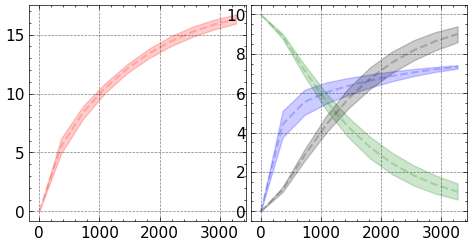

In [8]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    var_names=["y_hat"],
)
display(post_data)

post_data[:, 0, :] *= 1000

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)

# plot_true_data(axs, times, y_true, lw=2)

plot_true_data(
    axs,
    t_obs,
    post_data.values.mean(axis=2),
    lw=1.5,
    alpha=0.2,
)

axs[0, 0].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 0],
    np.percentile(post_data.values, 95, axis=2)[:, 0],
    color="red",
    alpha=0.2,
    zorder=0,
)

axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 1],
    np.percentile(post_data.values, 95, axis=2)[:, 1],
    color=["blue"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 2],
    np.percentile(post_data.values, 95, axis=2)[:, 2],
    color=["green"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 3],
    np.percentile(post_data.values, 95, axis=2)[:, 3],
    color=["black"],
    alpha=0.2,
    zorder=0,
)


plt.show()

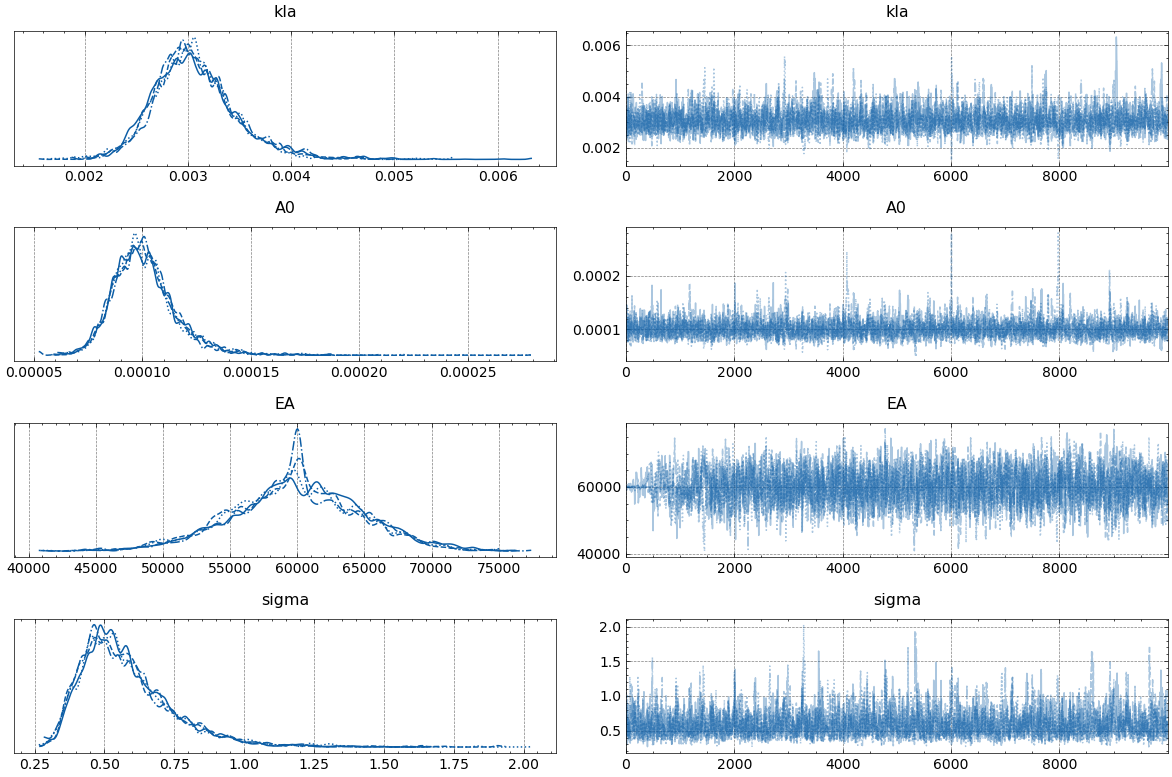

In [9]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A0",
        "EA",
        "sigma",
    ],
)
plt.show()

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")


Plotting sample 1/50
theta: (1000000.0, 250, np.float64(0.003542534100595043), np.float64(7.605128074115279e-05), np.float64(56720.39550783529))
Plotting sample 2/50
theta: (1000000.0, 250, np.float64(0.0031422362679860995), np.float64(9.451878047267801e-05), np.float64(61795.70050307293))
Plotting sample 3/50
theta: (1000000.0, 250, np.float64(0.0033697791278644684), np.float64(7.892773400048765e-05), np.float64(57847.580398793485))
Plotting sample 4/50
theta: (1000000.0, 250, np.float64(0.0027347281707210923), np.float64(0.00010005754429832387), np.float64(58880.48380835346))
Plotting sample 5/50
theta: (1000000.0, 250, np.float64(0.0036355436505340483), np.float64(7.492909354480538e-05), np.float64(60537.45715835653))
Plotting sample 6/50
theta: (1000000.0, 250, np.float64(0.00344045135677198), np.float64(8.81371712241023e-05), np.float64(61715.251462530396))
Plotting sample 7/50
theta: (1000000.0, 250, np.float64(0.0036341012792097433), np.float64(8.355779693363425e-05), np.float64

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


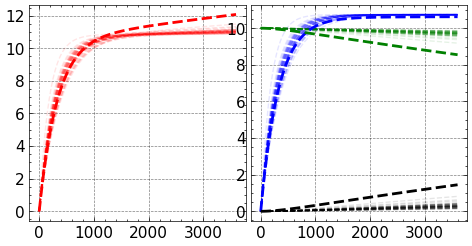

In [12]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=50,
    theta_indep=(10e5, 250),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[0, :, :])